--> Dataset loaded successfully from: /kaggle/input/datasets/billcampos/online-shoppers/online_shoppers_intention.csv
Dataset Shape: (12330, 18)

Numerical Features (14): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical Features (3): ['Month', 'VisitorType', 'Weekend']
Target Variable: Revenue

Training Set Size: 9864 samples
Testing Set Size:  2466 samples

=================== MODEL COMPARISON TABLE ===================
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.8812     0.7432  0.3560    0.4814
                KNN    0.8731     0.6456  0.4005    0.4943
      Decision Tree    0.8994     0.7107  0.5916    0.6457
      Random Forest    0.8998     0.7509  0.5288    0.6206



TypeError: ConfusionMatrixDisplay.plot() got an unexpected keyword argument 'cbar'

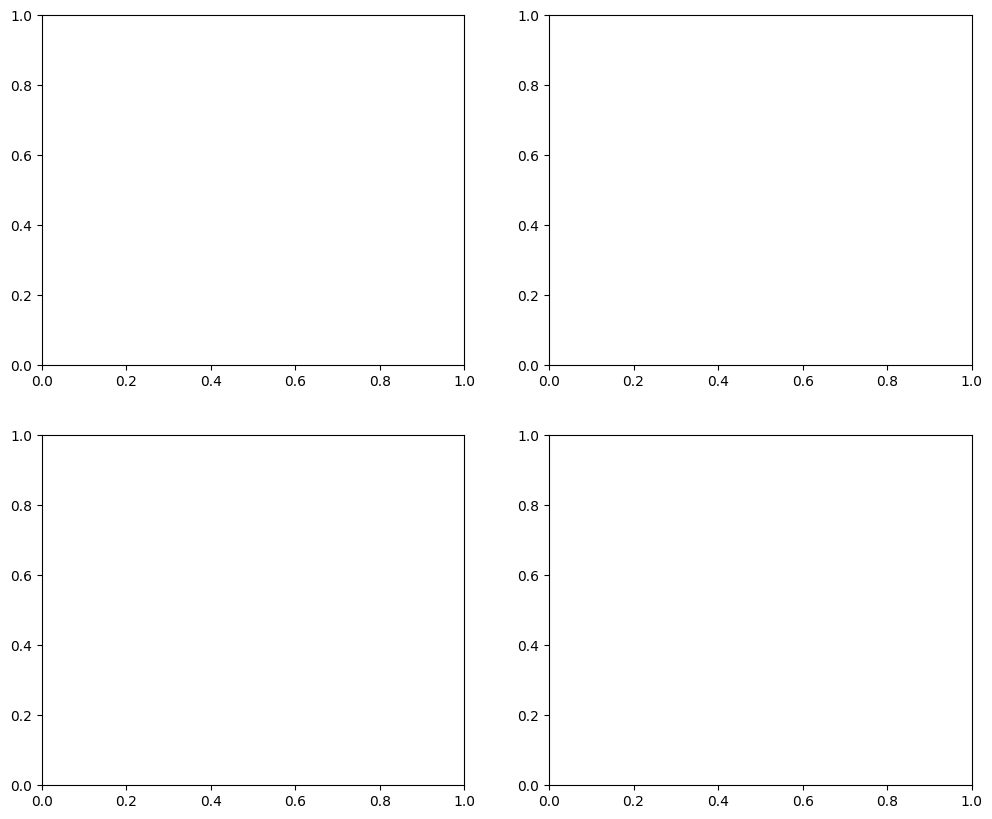

In [8]:
# ==============================================================================
# COURSE: Introduction to Data Science
# TITLE: Apply and Compare Machine Learning Models on a Real-World Dataset
# PROBLEM: Online Shoppers Purchasing Intention (Classification)
# ==============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay
)

# ==========================================
# 1. DEFINE THE PROBLEM & LOAD DATASET
# ==========================================
# Dataset: Online Shoppers Purchasing Intention Dataset
# Problem Type: BINARY CLASSIFICATION
# Target Variable (y): 'Revenue' (1 = Purchase, 0 = No Purchase)
# Features (X): User behavior metrics (PageValues, BounceRates, etc.) & session info

file_name = "online_shoppers_intention.csv"

# Robust file searching for Kaggle, Colab, or local environments
found_files = glob.glob(f"/kaggle/input/**/{file_name}", recursive=True)
if not found_files:
    found_files = glob.glob(f"./**/{file_name}", recursive=True)

if found_files:
    file_path = found_files[0]
    print(f"--> Dataset loaded successfully from: {file_path}")
    df = pd.read_csv(file_path)
else:
    raise FileNotFoundError(
        f"Could not find '{file_name}'. Please ensure the file is uploaded to your environment."
    )

print(f"Dataset Shape: {df.shape}\n")

# Specify Target Column
target_col = 'Revenue'

# Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col].astype(int)  # Convert True/False boolean to 1/0

# Automatically separate numerical and categorical columns
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f"Numerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_features)}): {cat_features}")
print(f"Target Variable: {target_col}\n")

# ==========================================
# 2. TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Set Size: {X_train.shape[0]} samples")
print(f"Testing Set Size:  {X_test.shape[0]} samples\n")

# Preprocessing Pipelines for Numerical and Categorical Data
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

# Fit-transform on train data; transform test data
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# ==========================================
# 3. APPLY SUITABLE MODELS
# ==========================================
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

# ==========================================
# 4. EVALUATE MODELS
# ==========================================
results = []
confusion_matrices = {}

for name, model in models.items():
    # Train model
    model.fit(X_train_prep, y_train)
    
    # Predict test data
    y_pred = model.predict(X_test_prep)
    
    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    # Store Confusion Matrix
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

# ==========================================
# 5. COMPARISON TABLE & VISUALIZATIONS
# ==========================================
results_df = pd.DataFrame(results)

print("=================== MODEL COMPARISON TABLE ===================")
print(results_df.to_string(index=False))
print("==============================================================\n")

# Plot Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Purchase', 'Purchase'])
    disp.plot(ax=axes[idx], cmap='Blues', cbar=False)
    axes[idx].set_title(f'Confusion Matrix: {name}')

plt.tight_layout()
plt.show()

# Evaluate Overfitting / Underfitting on the best model (Random Forest)
best_model = models['Random Forest']
train_acc = best_model.score(X_train_prep, y_train)
test_acc = best_model.score(X_test_prep, y_test)

print("================ OVERFITTING CHECK (Random Forest) ================")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy:  {test_acc:.4f}")
print("================================================================")
